In [ ]:
# Load the libraries used throughout this lab.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score

In [ ]:
#look up csv file on my computer
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [ ]:
#Show Data
bank_df = pd.concat([X, y], axis=1)
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [ ]:
#find unique poutcome
bank_df.poutcome.unique()

array([nan, 'failure', 'other', 'success'], dtype=object)

In [ ]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
# drop columns "duration", "campaign", "day_of_week", "month", and "contact" since they
# are unknown before the call.
cols = ['duration','campaign','day_of_week','month','contact']
bank_df.drop(columns=cols, inplace=True)
bank_df

,age,job,marital,education,default,balance,housing,loan,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,-1,0,NaN,no


In [ ]:
#unique poutcome
bank_df.poutcome.unique()

array([nan, 'failure', 'other', 'success'], dtype=object)

In [ ]:
model_df = bank_df.copy()

# Convert binary columns directly to 0/1
binary_cols = ["default", "housing", "loan", "y"]

for col in binary_cols:
    model_df[col] = model_df[col].map({"no": 0, "yes": 1})

# Distinguish no previous contact from an unknown outcome
no_history = (
    model_df["poutcome"].isna()
    & model_df["previous"].eq(0)
)
model_df.loc[no_history, "poutcome"] = "no_previous_contact"

# Mark all remaining categorical predictors as categorical
cat_cols = [
    "job", "marital", "education", "poutcome"
]

for col in cat_cols:
    model_df[col] = (
        model_df[col]
        .fillna("unknown")
        .astype("category")
    )

# Create one dummy column per category
model_df = pd.get_dummies(
    model_df,
    prefix_sep="_",
    drop_first=False,
    dtype=int
)

model_df.head()

,age,default,balance,housing,loan,pdays,previous,y,job_admin.,job_blue-collar,...,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,poutcome_failure,poutcome_no_previous_contact,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,-1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
1,44,0,29,1,0,-1,0,0,0,0,...,1,0,1,0,0,0,1,0,0,0
2,33,0,2,1,1,-1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,47,0,1506,1,0,-1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,33,0,1,0,0,-1,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0


In [ ]:
#find the correlation between each attributes to y
corr_matrix = model_df.corr()
corr_matrix["y"].sort_values(ascending=False)

,y
y,1.000000
poutcome_success,0.306788
pdays,0.103621
previous,0.093236
job_retired,0.079245
job_student,0.076897
education_tertiary,0.066448
marital_single,0.063526
balance,0.052838
job_management,0.032919


In [ ]:
#see if categorical values are adjusted in model data
model_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 32 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   age                           45211 non-null  int64
 1   default                       45211 non-null  int64
 2   balance                       45211 non-null  int64
 3   housing                       45211 non-null  int64
 4   loan                          45211 non-null  int64
 5   pdays                         45211 non-null  int64
 6   previous                      45211 non-null  int64
 7   y                             45211 non-null  int64
 8   job_admin.                    45211 non-null  int64
 9   job_blue-collar               45211 non-null  int64
 10  job_entrepreneur              45211 non-null  int64
 11  job_housemaid                 45211 non-null  int64
 12  job_management                45211 non-null  int64
 13  job_retired                   4

In [ ]:
# Separate predictors and target
X = model_df.drop(columns="y")
y = model_df["y"]

model_df.head()

,age,default,balance,housing,loan,pdays,previous,y,job_admin.,job_blue-collar,...,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,poutcome_failure,poutcome_no_previous_contact,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,-1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
1,44,0,29,1,0,-1,0,0,0,0,...,1,0,1,0,0,0,1,0,0,0
2,33,0,2,1,1,-1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,47,0,1506,1,0,-1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,33,0,1,0,0,-1,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0


In [ ]:
# Check the data before modeling
assert X.select_dtypes(exclude=["number", "bool"]).empty
assert not X.isna().any().any()
assert y.isin([0, 1]).all()
assert y.nunique() == 2

In [ ]:
# Split into 60% training and 40% testing, exactly as in class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=1, stratify=y
)

In [ ]:
# Grow the full tree without additional depth or leaf-size restrictions.
full_clf = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=100,
    random_state=0
)
full_clf.fit(X_train, y_train)

print("Number of nodes:", full_clf.tree_.node_count)
print("Tree depth:", full_clf.get_depth())

Number of nodes: 15
Tree depth: 3


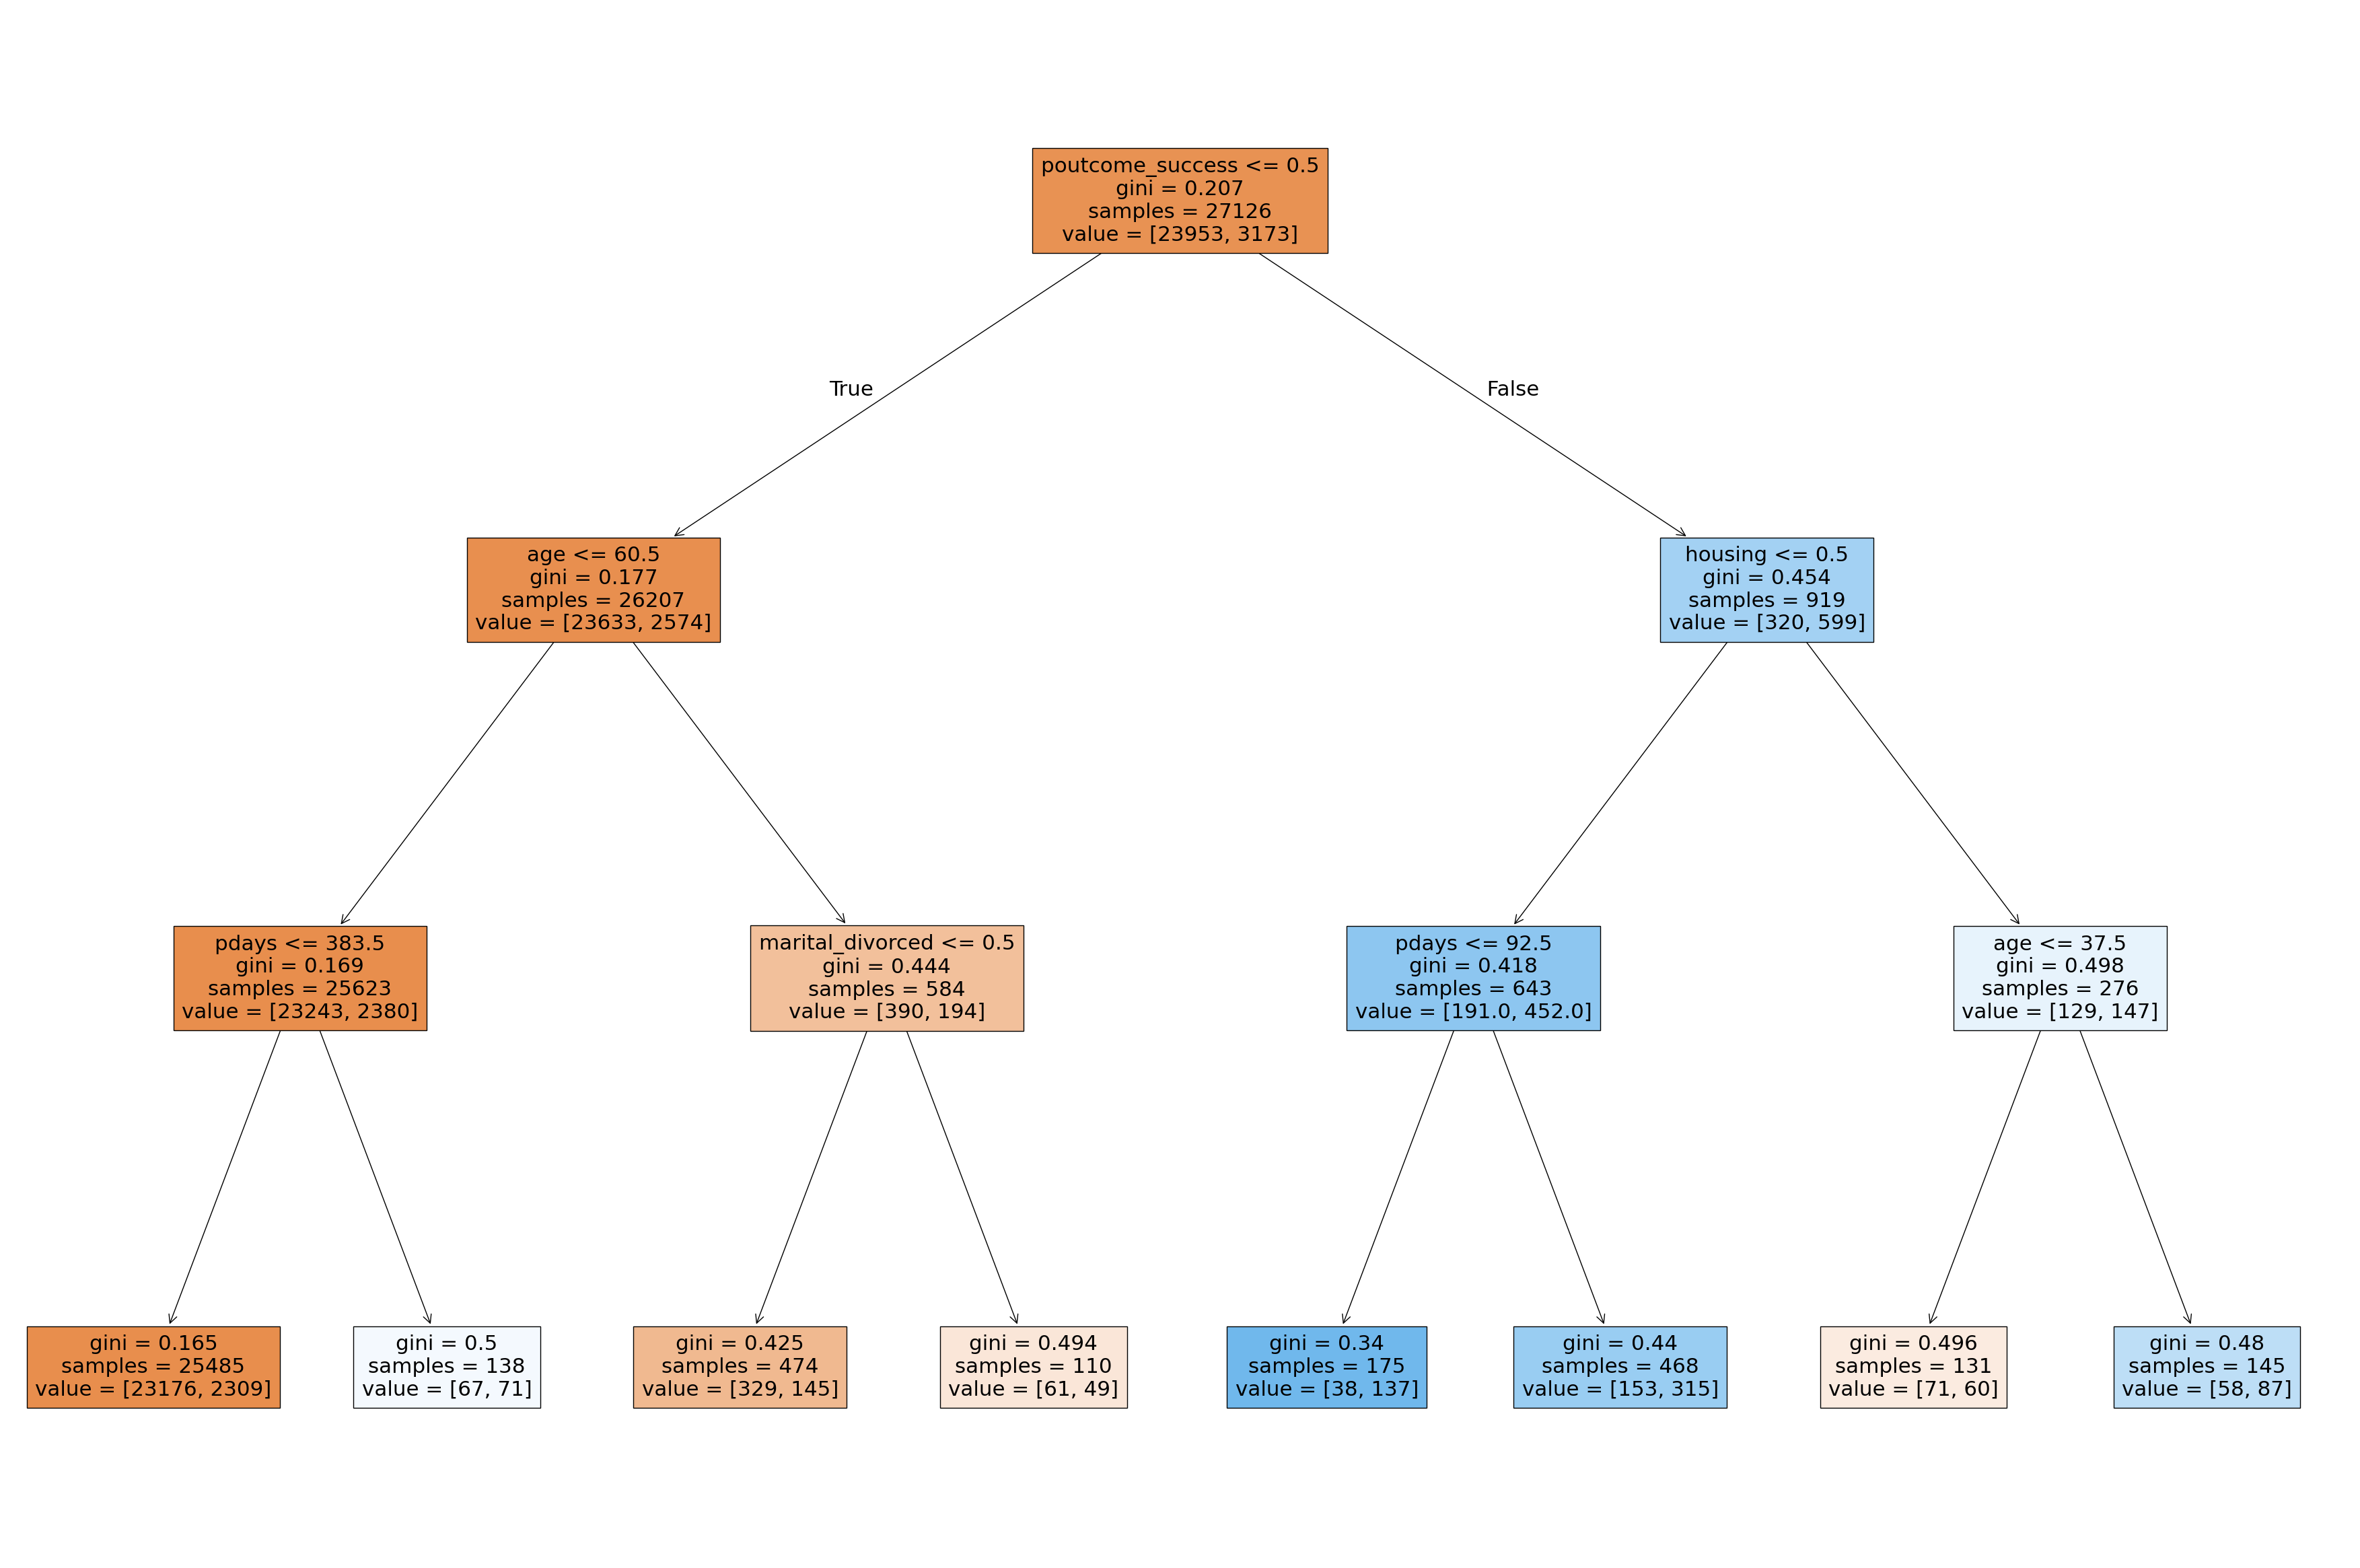

In [ ]:
# Draw the full tree; 'filled' colors each node by majority class.
plt.figure(figsize=(45, 30))
tree.plot_tree(full_clf, feature_names=X.columns, filled=True);

In [ ]:
# Predict subscription for the training and test customers separately.
y_pred_train = full_clf.predict(X_train)
y_pred_test = full_clf.predict(X_test)

In [ ]:
# Accuracy of the full tree on training and test sets.
train_score = accuracy_score(y_train, y_pred_train)
test_score = accuracy_score(y_test, y_pred_test)

print(
    "Accuracy score of full tree on training data =",
    round(train_score * 100, 1),
    "%"
)
print(
    "Accuracy score of full tree on testing data =",
    round(test_score * 100, 1),
    "%"
)

Accuracy score of full tree on training data = 89.4 %
Accuracy score of full tree on testing data = 89.1 %


In [ ]:
# Confusion matrices of the full tree on the training and test sets.
print("Confusion Matrix of full tree on train data:")
print(confusion_matrix(y_train, y_pred_train))

print("Confusion Matrix of full tree on test data:")
print(confusion_matrix(y_test, y_pred_test))

Confusion Matrix of full tree on train data:
[[23637   316]
 [ 2563   610]]
Confusion Matrix of full tree on test data:
[[15756   213]
 [ 1751   365]]


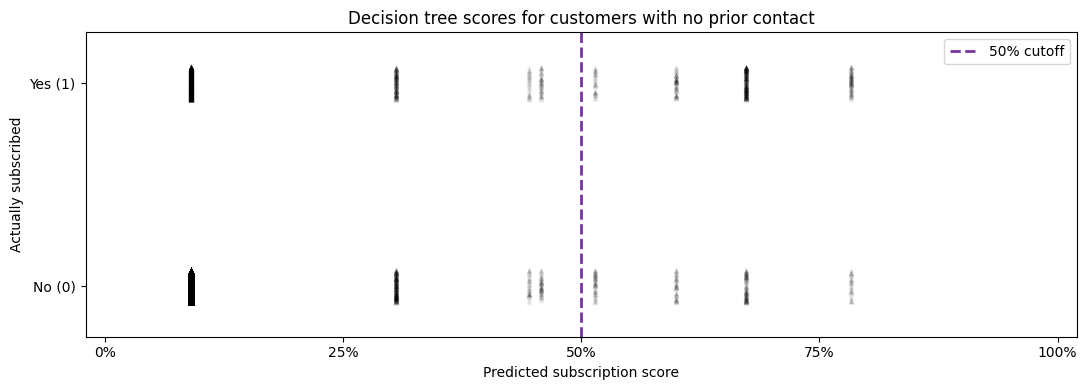

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

cutoff = 0.50

plot_data = pd.DataFrame({
    "score": full_clf.predict_proba(X_test)[:, 1],
    "actual": y_test.loc[X_test.index].to_numpy(),
})

# Add a little vertical spacing so tied scores are visible.
# The scores on the x-axis stay exactly as the tree predicted them.
rng = np.random.default_rng(42)
plot_data["plot_y"] = plot_data["actual"] + rng.uniform(
    -0.08, 0.08, size=len(plot_data)
)

fig, ax = plt.subplots(figsize=(11, 4))

ax.scatter(
    plot_data["score"],
    plot_data["plot_y"],
    marker="^",
    color="black",
    s=16,
    alpha=0.08,
    linewidths=0,
)

ax.axvline(
    cutoff, color="#7534a5", linestyle="--", linewidth=2,
    label=f"{cutoff:.0%} cutoff",
)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.25, 1.25)
ax.set_xticks([0, 0.25, 0.50, 0.75, 1])
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_yticks([0, 1], labels=["No (0)", "Yes (1)"])
ax.set_xlabel("Predicted subscription score")
ax.set_ylabel("Actually subscribed")
ax.set_title("Decision tree scores for customers with no prior contact")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

def evaluate_predictions(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    def divide(a, b):
        return a / b if b else 0.0

    return {
        "Accuracy": divide(tp + tn, tp + tn + fp + fn),
        "Precision": divide(tp, tp + fp),
        "Recall / TPR": divide(tp, tp + fn),
        "FPR": divide(fp, fp + tn),
        "Specificity": divide(tn, tn + fp),
        "F1": divide(2 * tp, 2 * tp + fp + fn),
        "Selected fraction": divide(tp + fp, tp + tn + fp + fn)
    }

current_results = pd.DataFrame({
    "Training": evaluate_predictions(y_train, y_pred_train),
    "Test": evaluate_predictions(y_test, y_pred_test)
}).T

# Display metrics as percentages
(current_results * 100).round(2)

,Accuracy,Precision,Recall / TPR,FPR,Specificity,F1,Selected fraction
Training,89.39,65.87,19.22,1.32,98.68,29.76,3.41
Test,89.14,63.15,17.25,1.33,98.67,27.10,3.20


In [ ]:
# Load the random forest classifier.
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Grow 500 trees using bootstrap samples of customers
# and random subsets of features at each split.
rf = RandomForestClassifier(
    n_estimators=500,  # number of trees in the forest
    random_state=0,
    criterion="gini",
    n_jobs=-1         # use every available CPU core
)

rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0)

In [ ]:
# Accuracy and confusion matrix of the random forest on the test set.
print("Accuracy=", accuracy_score(y_test, rf.predict(X_test)))

confusion_matrix(y_test, rf.predict(X_test))

Accuracy= 0.8770251589715233


array([[15440,   529],
       [ 1695,   421]])

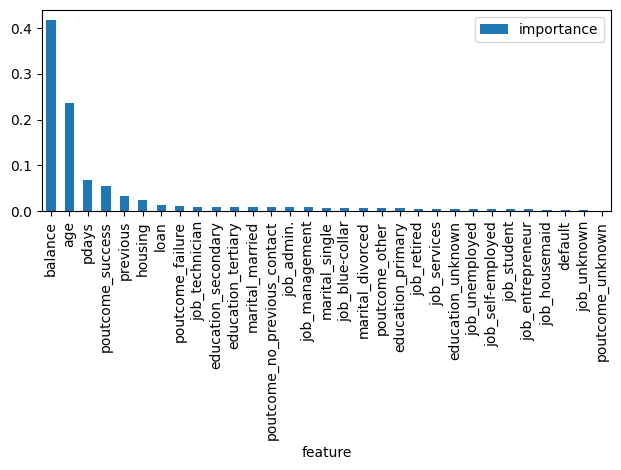

In [ ]:
# Rank features by their average contribution to reducing impurity.
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

importance_df.plot(kind="bar", x="feature")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# Try every combination using 5-fold cross-validation.
param_grid = {
    "max_depth": [3, 5, 10, 20],
    "min_samples_leaf": [20, 50, 100, 200],
    "min_impurity_decrease": [0, 0.0005, 0.001, 0.005, 0.01]
}

gridSearch = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Use only the training data to choose the settings.
gridSearch.fit(X_train, y_train)

print("Best cross-validation F1:", round(gridSearch.best_score_, 4))
print("Parameter values to achieve best F1:", gridSearch.best_params_)

Best cross-validation F1: 0.3015
Parameter values to achieve best F1: {'max_depth': 5, 'min_impurity_decrease': 0.0005, 'min_samples_leaf': 20}


In [ ]:
# The best tree is already fitted on all the training data.
best_clf = gridSearch.best_estimator_

# Predict outcomes for the test customers.
y_pred_test_f1 = best_clf.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred_test_f1), 4))
print("Test precision:", round(precision_score(y_test, y_pred_test_f1, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, y_pred_test_f1, zero_division=0), 4))
print("Test F1:", round(f1_score(y_test, y_pred_test_f1, zero_division=0), 4))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_test_f1, labels=[0, 1]))

Test accuracy: 0.8912
Test precision: 0.6107
Test recall: 0.1942
Test F1: 0.2947
Confusion matrix:
[[15707   262]
 [ 1705   411]]


In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve, accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

# Divide the training data into five temporary groups.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Predict each training customer's probability without training on that row.
cv_probabilities = cross_val_predict(
    clone(best_clf),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [ ]:
# Calculate precision and recall at each possible cutoff.
precision, recall, thresholds = precision_recall_curve(
    y_train,
    cv_probabilities
)

# The final precision/recall point has no corresponding threshold.
precision = precision[:-1]
recall = recall[:-1]

f1_scores = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros_like(precision),
    where=(precision + recall) != 0
)

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision,
    "Recall": recall,
    "F1": f1_scores
})

# If F1 scores tie, choose the higher threshold.
threshold_results = threshold_results.sort_values(
    ["F1", "Threshold"],
    ascending=[False, False]
)

best_threshold = float(threshold_results.iloc[0]["Threshold"])

print("Selected threshold:", best_threshold)
print("Best training cross-validation F1:",
      round(threshold_results.iloc[0]["F1"], 4))

# These values are proportions: 0.60 means 60%.
display(threshold_results.head(10).round(4))

Selected threshold: 0.2272108843537415
Best training cross-validation F1: 0.3754


,Threshold,Precision,Recall,F1
10,0.2272,0.4106,0.3457,0.3754
11,0.2434,0.4181,0.3284,0.3679
12,0.2442,0.4427,0.3104,0.3649
13,0.2500,0.4688,0.2931,0.3607
14,0.3207,0.5037,0.2789,0.3590
15,0.3219,0.5118,0.2657,0.3498
16,0.3373,0.5226,0.2518,0.3399
9,0.1179,0.2802,0.4248,0.3377
17,0.3397,0.5295,0.2433,0.3334
18,0.3460,0.5492,0.2323,0.3265


In [ ]:
# Fit the selected tree settings on all the training data.
final_tree = clone(best_clf)
final_tree.fit(X_train, y_train)

test_probabilities = final_tree.predict_proba(X_test)[:, 1]

# Compare the original prediction rule with the selected threshold.
default_predictions = final_tree.predict(X_test)
tuned_predictions = (
    test_probabilities >= best_threshold
).astype(int)

def evaluate_threshold(y_true, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "FPR": fp / (fp + tn) if fp + tn else 0,
        "Selected fraction": np.mean(predictions == 1)
    }

comparison = pd.DataFrame({
    "Default cutoff": evaluate_threshold(
        y_test, default_predictions
    ),
    "F1-tuned cutoff": evaluate_threshold(
        y_test, tuned_predictions
    )
}).T

display(comparison.round(4))

print("Confusion matrix with the tuned cutoff:")
print(confusion_matrix(y_test, tuned_predictions, labels=[0, 1]))

,Accuracy,Precision,Recall,F1,FPR,Selected fraction
Default cutoff,0.8912,0.6107,0.1942,0.2947,0.0164,0.0372
F1-tuned cutoff,0.8649,0.4134,0.3686,0.3897,0.0693,0.1043


Confusion matrix with the tuned cutoff:
[[14862  1107]
 [ 1336   780]]


In [ ]:
from sklearn.metrics import mean_squared_error

# RMSE for the default and tuned classification predictions.
default_rmse = np.sqrt(
    mean_squared_error(y_test, default_predictions)
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

print("Default cutoff RMSE:", round(default_rmse, 4))
print("Tuned cutoff RMSE:", round(tuned_rmse, 4))

Default cutoff RMSE: 0.3246
Tuned cutoff RMSE: 0.3325
